# Model 05 · Will I take my phone to the bathroom?
Binary classifier. Intentionally the simplest model in the lab: some questions deserve logistic regression.

In [1]:
import sys
sys.path.insert(0, "../_shared")
try:
    import kit
except ImportError:
    from google.colab import files; files.upload(); import kit
from kit import *

## 1 · Dataset generator

In [2]:
def generate(n=5000, seed=SEED):
    r = np.random.default_rng(seed)
    d = pd.DataFrame({
        "typical_minutes": np.round(np.clip(r.lognormal(1.9, 0.5, n), 1, 40), 1),
        "phone_in_hand": r.choice([0, 1], n, p=[.45, .55]),
        "boredom": r.integers(0, 11, n),
        "yt_notifications": np.clip(r.poisson(4, n), 0, 30),
        "battery": np.round(np.clip(r.beta(2.2, 1.6, n) * 100, 1, 100)),
        "hour": np.round(r.uniform(0, 24, n), 1)})
    habit = r.normal(0, 0.9, n)
    night = ((d.hour >= 22) | (d.hour < 3)).astype(float)
    logit = (-3.0 + 0.11 * d.typical_minutes + 2.1 * d.phone_in_hand + 0.28 * d.boredom + 0.07 * d.yt_notifications
             + 0.008 * (d.battery - 50) + 0.5 * night + 0.25 * d.phone_in_hand * (d.boredom > 6) + habit)
    d["takes_phone"] = (r.random(n) < sigmoid(logit + r.normal(0, 0.4, n))).astype(int)
    d["p_true"] = sigmoid(logit); return d

In [3]:
df = generate(5000); df.drop(columns="p_true").to_csv("dataset.csv", index=False)
print(df.shape, "| positive rate:", round(df.takes_phone.mean(), 3)); df.drop(columns="p_true").head()

(5000, 8) | positive rate: 0.641


,typical_minutes,phone_in_hand,boredom,yt_notifications,battery,hour,takes_phone
0,7.8,0,5,7,93.0,1.2,0
1,4.0,0,2,5,45.0,5.0,1
2,9.7,1,3,1,71.0,4.9,1
3,10.7,1,0,6,57.0,19.7,1
4,2.5,0,0,3,1.0,6.0,0


## 2 · Cleaning + EDA

nulls: 0 | duplicates: 0


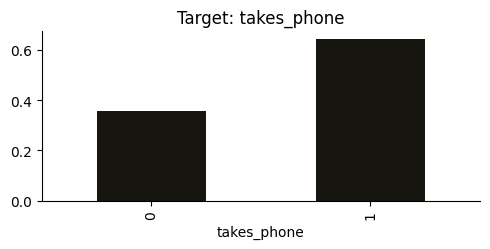

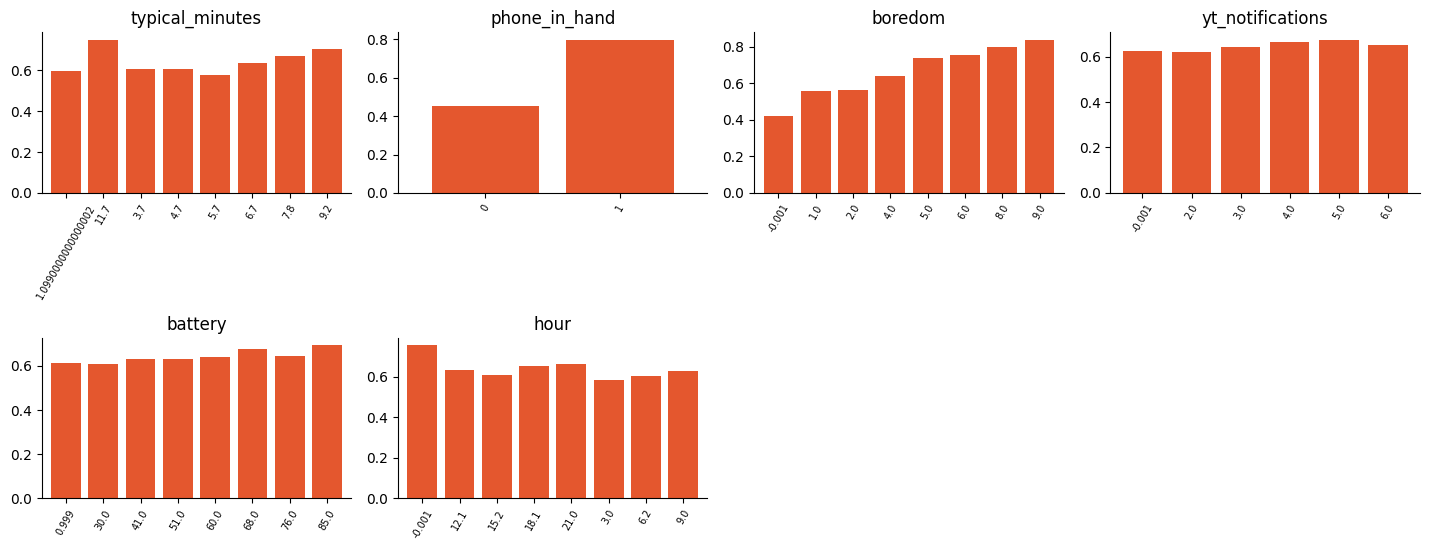

In [4]:
print("nulls:", int(df.isna().sum().sum()), "| duplicates:", int(df.duplicated().sum()))
INPUTS = [Num("typical_minutes", 1, 40), Num("phone_in_hand", 0, 1), Num("boredom", 0, 10), Num("yt_notifications", 0, 30),
          Num("battery", 0, 100), Num("hour", 0, 24, "cyc")]
RAW = [s["name"] for s in INPUTS]; eda(df, "takes_phone", RAW)

## 3 · Features, split, train

In [5]:
fz = Featurizer(INPUTS); tr, va, te = split3(df, "takes_phone")
Xtr, Xva, Xte = fz.transform(tr), fz.transform(va), fz.transform(te)
best, best_name, table = train_classifier(Xtr, tr.takes_phone, Xva, va.takes_phone, depth=7, leaf=20)
print("selected:", best_name); table.round(4)

selected: Logistic Regression


,model,val_log_loss,val_accuracy
0,Logistic Regression,0.5491,0.7160
1,Random Forest (isotonic-calibrated),0.7771,0.7053


## 4 · Test evaluation + importance

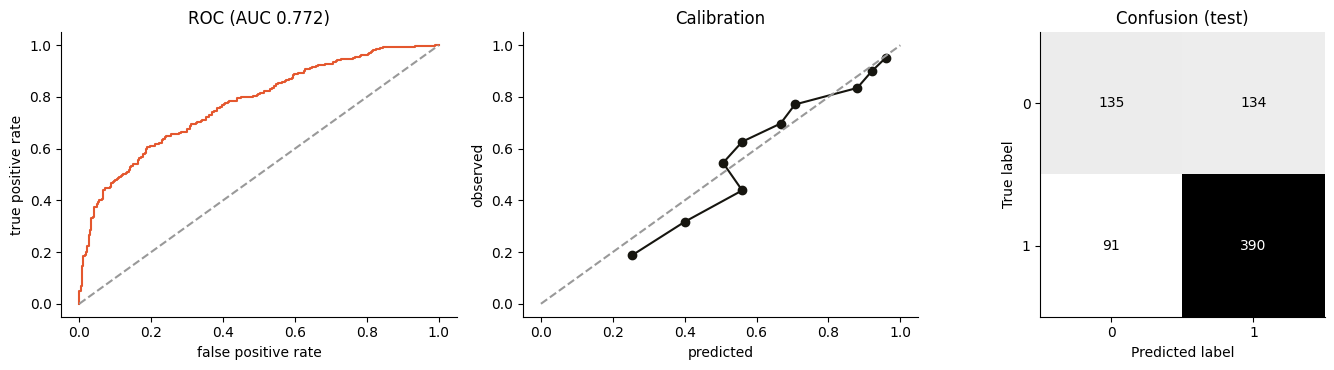

{'accuracy': 0.7,
 'roc_auc': 0.7716,
 'log_loss': 0.5405,
 'brier': 0.1842,
 'oracle_auc': 0.8341}

In [6]:
m = report_binary(best, Xte, te.takes_phone); m["oracle_auc"] = round(float(roc_auc_score(te.takes_phone, te.p_true)), 4); m

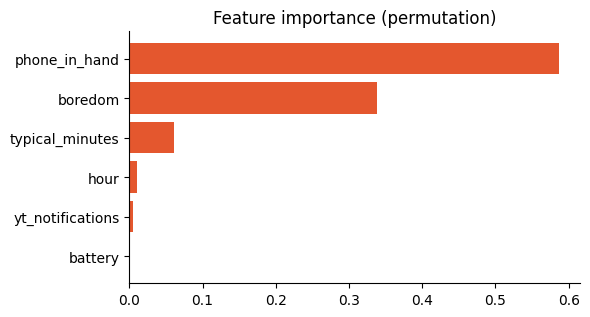

{'phone_in_hand': 0.5861,
 'boredom': 0.3383,
 'typical_minutes': 0.0609,
 'hour': 0.0102,
 'yt_notifications': 0.0045,
 'battery': 0.0}

In [7]:
imp = group_importance(lambda X: best.predict_proba(X)[:, 1], Xte, te.takes_phone.to_numpy(), fz.groups, lambda y, p: log_loss(y, p))
plot_importance(imp); imp

In [8]:
ex = pd.DataFrame([dict(typical_minutes=12, phone_in_hand=1, boredom=8, yt_notifications=9, battery=40, hour=22),
                   dict(typical_minutes=3, phone_in_hand=0, boredom=1, yt_notifications=0, battery=90, hour=8)])
ex["P(takes phone)"] = best.predict_proba(fz.transform(ex))[:, 1].round(3); ex

,typical_minutes,phone_in_hand,boredom,yt_notifications,battery,hour,P(takes phone)
0,12,1,8,9,40,22,0.958
1,3,0,1,0,90,8,0.144


## 5 · Export + verify

In [9]:
head = export_head(best, labels=["no", "yes"])
meta = make_metadata("v1.0", SEED, len(df), {"train": len(tr), "val": len(va), "test": len(te)},
    {"phone": {"algorithm": best_name, "task": "binary", "metrics": m, "candidates": table.round(4).to_dict("records")}}, imp,
    ["Synthetic data: metrics measure recovery of the generator, not real bathroom habits.", "Hidden habit trait caps accuracy; see oracle_auc."], "generate() in train.ipynb")
write_artifacts("model", "bathroom-phone", "Will I take my phone to the bathroom?", fz, tr, {"phone": head}, {"phone": best}, meta, te[RAW])

wrote model (31 KB total) | export error vs sklearn: {'phone': 6.756143422492755e-10}


{'phone': 6.756143422492755e-10}